In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision import models, transforms

from PIL import Image

# Captum provides the Integrated Gradients implementation
from captum.attr import IntegratedGradients

# Find project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

# Define project directories
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

MODEL_DIR = PROJECT_ROOT / "results" / "models"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"

EXPLANATION_DIR = (
    PROJECT_ROOT / "results" / "explanations" / "integrated_gradients"
)

# Create output directory
EXPLANATION_DIR.mkdir(parents=True, exist_ok=True)

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Class order used during training
class_names = ["plain", "satin", "twill"]

print("Project root:", PROJECT_ROOT)
print("Device:", device)
print("Integrated Gradients output directory:", EXPLANATION_DIR)
print("Model directory exists:", MODEL_DIR.exists())
print("Captum IntegratedGradients imported successfully.")

Project root: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L
Device: cpu
Integrated Gradients output directory: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\explanations\integrated_gradients
Model directory exists: True
Captum IntegratedGradients imported successfully.


Load fold information and predictions

In [2]:
# Load five-fold split information
folds_df = pd.read_csv(
    PROCESSED_DIR / "folds.csv"
)

# Load original model predictions from Notebook 03
predictions_df = pd.read_csv(
    METRICS_DIR / "combined_test_predictions.csv"
)

# Display sample records
print("Fold information:")
display(folds_df.head())

print("\nOriginal model predictions:")
display(predictions_df.head())

# Check dataset sizes
print("\nTotal images:", len(folds_df))
print("Total predictions:", len(predictions_df))

# Check images per test fold
print("\nImages per test fold:")
print(
    folds_df["test_fold"]
    .value_counts()
    .sort_index()
)

Fold information:


,image_filename,Texture,group_id,test_fold
0,W001.jpg,twill,10,2
1,W002.jpg,twill,10,2
2,W003.jpg,twill,10,2
3,W004.jpg,twill,10,2
4,W005.jpg,twill,10,2



Original model predictions:


,image_filename,actual_class,predicted_class,confidence,fold,correct
0,W006.jpg,twill,twill,0.970566,1,True
1,W007.jpg,twill,twill,0.698218,1,True
2,W008.jpg,twill,twill,0.977882,1,True
3,W009.jpg,twill,twill,0.992629,1,True
4,W010.jpg,twill,twill,0.995661,1,True



Total images: 130
Total predictions: 130

Images per test fold:
test_fold
1    27
2    23
3    30
4    26
5    24
Name: count, dtype: int64


Verify fold assignments

In [3]:
# Compare fold assignments with original predictions
fold_check = folds_df[
    ["image_filename", "test_fold"]
].merge(
    predictions_df[
        ["image_filename", "fold"]
    ],
    on="image_filename",
    how="inner"
)

# Check whether fold numbers match
fold_check["fold_matches"] = (
    fold_check["test_fold"] == fold_check["fold"]
)

# Display verification results
print("Total matched images:", len(fold_check))

print(
    "Matching fold assignments:",
    fold_check["fold_matches"].sum()
)

print(
    "Mismatched fold assignments:",
    (~fold_check["fold_matches"]).sum()
)

# Display any mismatches
display(
    fold_check[fold_check["fold_matches"] == False]
)

Total matched images: 130
Matching fold assignments: 130
Mismatched fold assignments: 0


,image_filename,test_fold,fold,fold_matches


Prepare image preprocessing and the baseline

In [4]:
# Define the image directory
IMAGE_DIR = DATA_DIR / "raw" / "images"

# Use the same preprocessing as Notebook 02
preprocess = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Create a zero baseline
# Shape: one RGB image of size 224 x 224
baseline = torch.zeros(
    (1, 3, 224, 224),
    device=device
)

print("Image directory exists:", IMAGE_DIR.exists())
print("Preprocessing configured successfully.")
print("Baseline shape:", baseline.shape)
print("Baseline device:", baseline.device)

Image directory exists: True
Preprocessing configured successfully.
Baseline shape: torch.Size([1, 3, 224, 224])
Baseline device: cpu


Load the Fold 1 model and prepare W006.jpg

In [5]:
# Function to load a trained fold model
def load_fold_model(fold_number):

    checkpoint_path = (
        MODEL_DIR / f"resnet18_fold{fold_number}.pth"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(checkpoint_path)

    # Recreate ResNet-18 architecture
    fold_model = models.resnet18(weights=None)

    # Configure three output classes
    fold_model.fc = nn.Linear(
        fold_model.fc.in_features,
        len(class_names)
    )

    # Load trained weights
    state_dict = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    fold_model.load_state_dict(state_dict)

    fold_model = fold_model.to(device)
    fold_model.eval()

    return fold_model


# Load Fold 1 model
fold_number = 1
model = load_fold_model(fold_number)

# Select W006.jpg from Fold 1
sample_filename = "W006.jpg"

sample_row = folds_df[
    folds_df["image_filename"] == sample_filename
].iloc[0]

sample_actual_class = sample_row["Texture"]

# Load original image
sample_image_path = IMAGE_DIR / sample_filename
original_image = Image.open(
    sample_image_path
).convert("RGB")

# Apply training preprocessing
input_tensor = preprocess(original_image).unsqueeze(0).to(device)

# Get the original model prediction
with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)

predicted_index = torch.argmax(probabilities, dim=1).item()
predicted_class = class_names[predicted_index]
confidence = probabilities[0, predicted_index].item()

print("Model loaded: Fold", fold_number)
print("Image:", sample_filename)
print("Actual class:", sample_actual_class)
print("Predicted class:", predicted_class)
print("Confidence:", round(confidence, 4))
print("Input shape:", input_tensor.shape)

Model loaded: Fold 1
Image: W006.jpg
Actual class: twill
Predicted class: twill
Confidence: 0.9706
Input shape: torch.Size([1, 3, 224, 224])


Calculate Integrated Gradients

In [6]:
# Create the Integrated Gradients explainer
ig = IntegratedGradients(model)

# Calculate pixel contributions
attributions, convergence_delta = ig.attribute(
    inputs=input_tensor,
    baselines=baseline,
    target=predicted_index,
    n_steps=50,
    method="gausslegendre",
    return_convergence_delta=True
)

# Display attribution information
print("Attributions shape:", attributions.shape)

print("Minimum attribution:", attributions.min().item())
print("Maximum attribution:", attributions.max().item())

print("Convergence delta:", convergence_delta.item())

Attributions shape: torch.Size([1, 3, 224, 224])
Minimum attribution: -0.1248871460556984
Maximum attribution: 0.13823726773262024
Convergence delta: -0.026943206787109375


Visualise Integrated Gradients

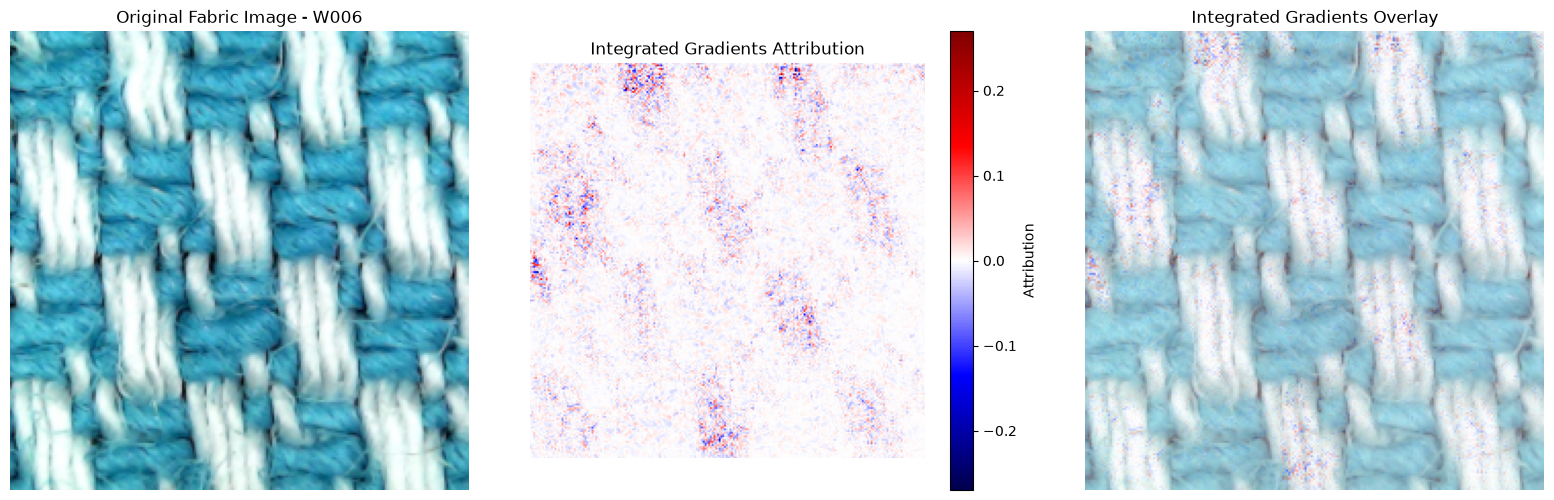

In [7]:
# Convert attributions into a NumPy array
attribution_array = attributions[0].detach().cpu().numpy()

# Combine the RGB channel contributions
attribution_map = attribution_array.sum(axis=0)

# Prepare the original fabric image
display_image = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((224, 224))
])(original_image)

display_image = np.array(display_image)

# Use symmetric limits to show positive and negative contributions
limit = np.abs(attribution_map).max()

# Display results
plt.figure(figsize=(16, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(display_image)
plt.title("Original Fabric Image - W006")
plt.axis("off")

# Signed attribution map
plt.subplot(1, 3, 2)
plt.imshow(
    attribution_map,
    cmap="seismic",
    vmin=-limit,
    vmax=limit
)
plt.colorbar(label="Attribution")
plt.title("Integrated Gradients Attribution")
plt.axis("off")

# Overlay
plt.subplot(1, 3, 3)
plt.imshow(display_image)
plt.imshow(
    attribution_map,
    cmap="seismic",
    alpha=0.45,
    vmin=-limit,
    vmax=limit
)
plt.title("Integrated Gradients Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Examine attribution strength

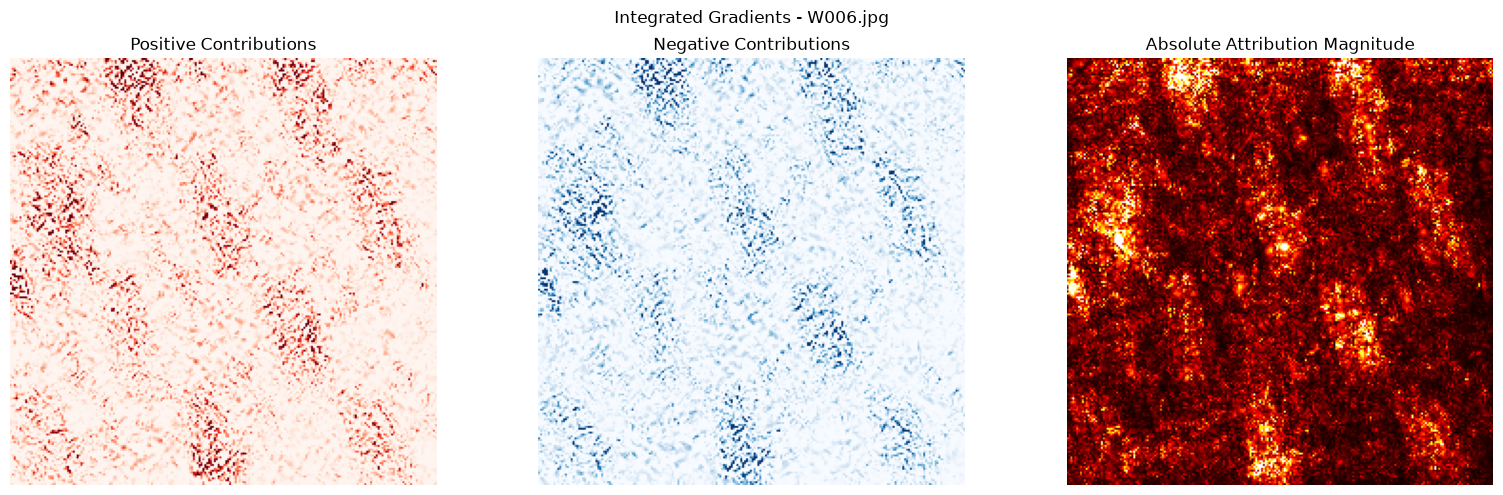

In [8]:
# Separate positive and negative contributions
positive_map = np.maximum(attribution_map, 0)
negative_map = np.maximum(-attribution_map, 0)

# Calculate total absolute attribution per pixel
absolute_map = np.abs(attribution_array).sum(axis=0)

# Use the 99th percentile to reduce the effect of extreme values
positive_limit = np.percentile(positive_map, 99)
negative_limit = np.percentile(negative_map, 99)
absolute_limit = np.percentile(absolute_map, 99)

# Display attribution maps
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(positive_map, cmap="Reds", vmin=0, vmax=positive_limit)
axes[0].set_title("Positive Contributions")

axes[1].imshow(negative_map, cmap="Blues", vmin=0, vmax=negative_limit)
axes[1].set_title("Negative Contributions")

axes[2].imshow(absolute_map, cmap="hot", vmin=0, vmax=absolute_limit)
axes[2].set_title("Absolute Attribution Magnitude")

for ax in axes:
    ax.axis("off")

plt.suptitle("Integrated Gradients - W006.jpg")
plt.tight_layout()
plt.show()

Check whether 50 integration steps are enough

In [9]:
# Test different numbers of integration steps
step_values = [50, 100, 200]

convergence_results = []
ig_attributions = {}

for steps in step_values:

    print(f"Calculating Integrated Gradients with {steps} steps...")

    # Calculate attributions
    test_attributions, delta = ig.attribute(
        inputs=input_tensor,
        baselines=baseline,
        target=predicted_index,
        n_steps=steps,
        method="gausslegendre",
        return_convergence_delta=True
    )

    # Save attribution result for comparison
    ig_attributions[steps] = (
        test_attributions[0]
        .detach()
        .cpu()
        .numpy()
        .sum(axis=0)
    )

    # Record convergence information
    convergence_results.append({
        "integration_steps": steps,
        "convergence_delta": delta.item(),
        "absolute_delta": abs(delta.item())
    })

# Display comparison
convergence_df = pd.DataFrame(convergence_results)

display(convergence_df)

Calculating Integrated Gradients with 50 steps...
Calculating Integrated Gradients with 100 steps...
Calculating Integrated Gradients with 200 steps...


,integration_steps,convergence_delta,absolute_delta
0,50,-0.026943,0.026943
1,100,0.002044,0.002044
2,200,0.008654,0.008654


Compare attribution maps

Attribution map correlation:


,50 steps,100 steps,200 steps
50 steps,1.000000,0.998895,0.999176
100 steps,0.998895,1.000000,0.999723
200 steps,0.999176,0.999723,1.000000


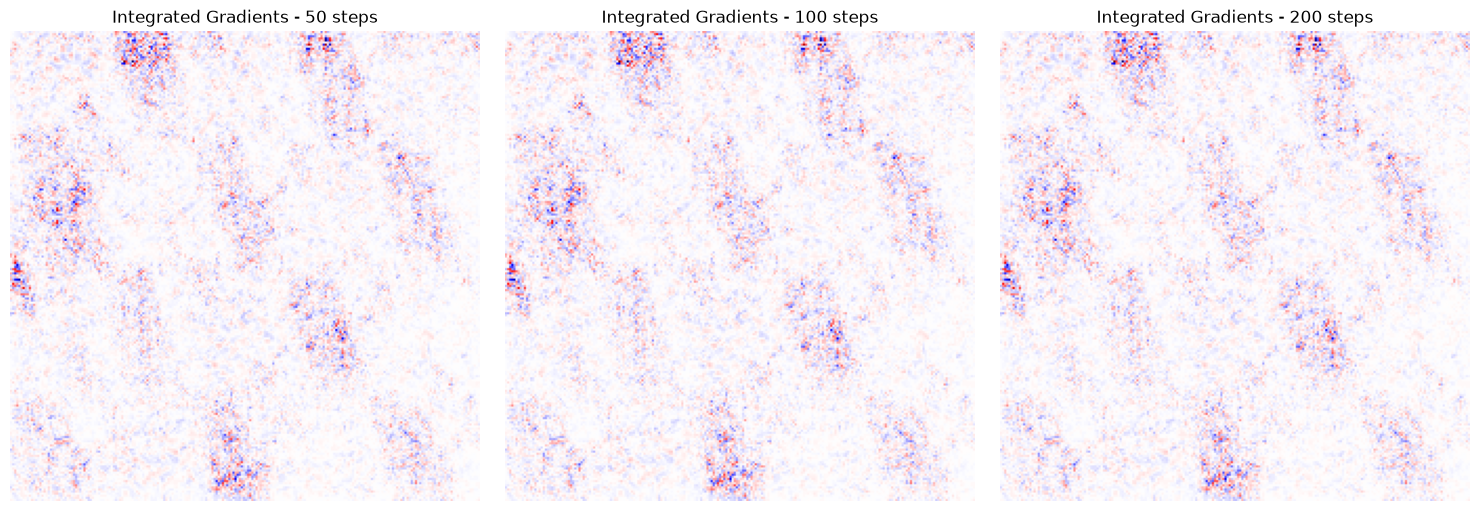

In [10]:
# Compare attribution maps generated using different step counts

maps = [
    ig_attributions[50].flatten(),
    ig_attributions[100].flatten(),
    ig_attributions[200].flatten()
]

# Calculate Pearson correlation between attribution maps
correlation_matrix = np.corrcoef(maps)

correlation_df = pd.DataFrame(
    correlation_matrix,
    index=["50 steps", "100 steps", "200 steps"],
    columns=["50 steps", "100 steps", "200 steps"]
)

print("Attribution map correlation:")
display(correlation_df)

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, steps in zip(axes, step_values):

    attribution_map = ig_attributions[steps]

    limit = np.abs(attribution_map).max()

    ax.imshow(
        attribution_map,
        cmap="seismic",
        vmin=-limit,
        vmax=limit
    )

    ax.set_title(f"Integrated Gradients - {steps} steps")
    ax.axis("off")

plt.tight_layout()
plt.show()

Test different fabric classes

In [11]:
# Prepare predictions for representative sample selection
predictions_check = predictions_df.copy()

predictions_check["actual_class"] = (
    predictions_check["actual_class"]
    .astype(str)
    .str.strip()
    .str.lower()
)

selected_samples = []
used_folds = set()

# Select one image per actual fabric class
# Each image must come from a different fold
for class_name in class_names:

    candidates = predictions_check[
        (predictions_check["actual_class"] == class_name) &
        (~predictions_check["fold"].isin(used_folds))
    ]

    if candidates.empty:
        raise ValueError(
            f"No unused-fold sample found for {class_name}"
        )

    sample = candidates.iloc[0]

    selected_samples.append(sample)
    used_folds.add(int(sample["fold"]))

# Create representative sample table
representative_df = pd.DataFrame(selected_samples)

print("Selected representative images:")
display(
    representative_df[
        [
            "image_filename",
            "actual_class",
            "predicted_class",
            "confidence",
            "fold"
        ]
    ]
)

Selected representative images:


,image_filename,actual_class,predicted_class,confidence,fold
6,W047.jpg,plain,satin,0.902733,1
42,W097.jpg,satin,satin,0.998524,2
55,W037.jpg,twill,twill,0.945609,3


Compare integration steps on all three images

In [12]:

# Compare Integrated Gradients convergence across three representative images

step_values = [50, 100, 200]

representative_convergence = []
representative_correlations = []

for _, sample in representative_df.iterrows():

    filename = sample["image_filename"]
    fold_number = int(sample["fold"])

    actual_class = str(sample["actual_class"]).lower()
    expected_prediction = str(sample["predicted_class"]).lower()

    print(f"\nProcessing {filename} using Fold {fold_number} model")

    # Load the correct fold-specific model
    sample_model = load_fold_model(fold_number)

    # Create Integrated Gradients explainer for this model
    sample_ig = IntegratedGradients(sample_model)

    # Load and preprocess image
    image = Image.open(
        IMAGE_DIR / filename
    ).convert("RGB")

    sample_tensor = preprocess(image).unsqueeze(0).to(device)

    # Get prediction from the loaded fold model
    with torch.no_grad():
        outputs = sample_model(sample_tensor)
        probabilities = torch.softmax(outputs, dim=1)

    predicted_index = probabilities.argmax(dim=1).item()
    predicted_class = class_names[predicted_index]

    # Verify original prediction
    prediction_matches = predicted_class == expected_prediction

    print("Actual class:", actual_class)
    print("Predicted class:", predicted_class)
    print("Original prediction matches:", prediction_matches)

    if not prediction_matches:
        raise ValueError(
            f"Prediction mismatch for {filename}. "
            "Check the correct checkpoint and preprocessing."
        )

    # Generate attributions using different integration steps
    sample_maps = {}

    for steps in step_values:

        print(f"  Calculating with {steps} steps...")

        attributions, delta = sample_ig.attribute(
            inputs=sample_tensor,
            baselines=baseline,
            target=predicted_index,
            n_steps=steps,
            method="gausslegendre",
            internal_batch_size=20,
            return_convergence_delta=True
        )

        # Combine RGB channel attributions
        attribution_map = (
            attributions[0]
            .detach()
            .cpu()
            .numpy()
            .sum(axis=0)
        )

        sample_maps[steps] = attribution_map

        representative_convergence.append({
            "image_filename": filename,
            "actual_class": actual_class,
            "predicted_class": predicted_class,
            "fold": fold_number,
            "integration_steps": steps,
            "convergence_delta": delta.item(),
            "absolute_delta": abs(delta.item())
        })

    # Compare attribution maps
    for first_step, second_step in [
        (50, 100),
        (50, 200),
        (100, 200)
    ]:

        correlation = np.corrcoef(
            sample_maps[first_step].flatten(),
            sample_maps[second_step].flatten()
        )[0, 1]

        representative_correlations.append({
            "image_filename": filename,
            "comparison": f"{first_step} vs {second_step}",
            "correlation": correlation
        })


# Display convergence results
representative_convergence_df = pd.DataFrame(
    representative_convergence
)

print("\nConvergence comparison:")
display(
    representative_convergence_df[
        [
            "image_filename",
            "fold",
            "integration_steps",
            "convergence_delta",
            "absolute_delta"
        ]
    ]
)

# Display attribution similarity
representative_correlations_df = pd.DataFrame(
    representative_correlations
)

print("\nAttribution map correlations:")
display(representative_correlations_df)



Processing W047.jpg using Fold 1 model
Actual class: plain
Predicted class: satin
Original prediction matches: True
  Calculating with 50 steps...
  Calculating with 100 steps...
  Calculating with 200 steps...

Processing W097.jpg using Fold 2 model
Actual class: satin
Predicted class: satin
Original prediction matches: True
  Calculating with 50 steps...
  Calculating with 100 steps...
  Calculating with 200 steps...

Processing W037.jpg using Fold 3 model
Actual class: twill
Predicted class: twill
Original prediction matches: True
  Calculating with 50 steps...
  Calculating with 100 steps...
  Calculating with 200 steps...

Convergence comparison:


,image_filename,fold,integration_steps,convergence_delta,absolute_delta
0,W047.jpg,1,50,0.120411,0.120411
1,W047.jpg,1,100,-0.044549,0.044549
2,W047.jpg,1,200,0.012610,0.012610
3,W097.jpg,2,50,0.117335,0.117335
4,W097.jpg,2,100,0.046719,0.046719
5,W097.jpg,2,200,0.037489,0.037489
6,W037.jpg,3,50,-0.236265,0.236265
7,W037.jpg,3,100,0.198439,0.198439
8,W037.jpg,3,200,-0.048435,0.048435



Attribution map correlations:


,image_filename,comparison,correlation
0,W047.jpg,50 vs 100,0.998665
1,W047.jpg,50 vs 200,0.999050
2,W047.jpg,100 vs 200,0.999698
3,W097.jpg,50 vs 100,0.998061
4,W097.jpg,50 vs 200,0.998573
5,W097.jpg,100 vs 200,0.999446
6,W037.jpg,50 vs 100,0.998614
7,W037.jpg,50 vs 200,0.999042
8,W037.jpg,100 vs 200,0.999635


In [13]:

# Additional convergence check using W037 and W097

additional_steps = [200, 300, 500]

additional_results = []

for filename in ["W037.jpg", "W097.jpg"]:

    # Find image information
    sample_row = predictions_df[
        predictions_df["image_filename"] == filename
    ].iloc[0]

    fold_number = int(sample_row["fold"])

    # Load corresponding model
    sample_model = load_fold_model(fold_number)
    sample_ig = IntegratedGradients(sample_model)

    # Load and preprocess image
    sample_image = Image.open(
        IMAGE_DIR / filename
    ).convert("RGB")

    sample_tensor = preprocess(sample_image).unsqueeze(0).to(device)

    # Identify predicted class
    with torch.no_grad():
        outputs = sample_model(sample_tensor)
        probabilities = torch.softmax(outputs, dim=1)

    target_index = probabilities.argmax(dim=1).item()

    print(f"\nTesting {filename}, Fold {fold_number}")
    print("Predicted class:", class_names[target_index])

    for steps in additional_steps:

        _, delta = sample_ig.attribute(
            inputs=sample_tensor,
            baselines=baseline,
            target=target_index,
            n_steps=steps,
            method="gausslegendre",
            internal_batch_size=20,
            return_convergence_delta=True
        )

        additional_results.append({
            "image_filename": filename,
            "fold": fold_number,
            "integration_steps": steps,
            "convergence_delta": delta.item(),
            "absolute_delta": abs(delta.item())
        })

# Display results
additional_convergence_df = pd.DataFrame(additional_results)

print("\nAdditional convergence results:")
display(additional_convergence_df)



Testing W037.jpg, Fold 3
Predicted class: twill

Testing W097.jpg, Fold 2
Predicted class: satin

Additional convergence results:


,image_filename,fold,integration_steps,convergence_delta,absolute_delta
0,W037.jpg,3,200,-0.048435,0.048435
1,W037.jpg,3,300,-0.005164,0.005164
2,W037.jpg,3,500,-0.008333,0.008333
3,W097.jpg,2,200,0.037489,0.037489
4,W097.jpg,2,300,0.020035,0.020035
5,W097.jpg,2,500,0.000864,0.000864


Define Integrated Gradients configuration

In [14]:
# Integrated Gradients experimental configuration

IG_STEPS = 500
IG_METHOD = "gausslegendre"
IG_INTERNAL_BATCH_SIZE = 20

# Zero baseline in normalized input space
IG_BASELINE = baseline

# Output directory
IG_OUTPUT_DIR = EXPLANATION_DIR

print("Integrated Gradients configuration:")
print("Integration steps:", IG_STEPS)
print("Integration method:", IG_METHOD)
print("Internal batch size:", IG_INTERNAL_BATCH_SIZE)
print("Baseline shape:", IG_BASELINE.shape)
print("Output directory exists:", IG_OUTPUT_DIR.exists())

Integrated Gradients configuration:
Integration steps: 500
Integration method: gausslegendre
Internal batch size: 20
Baseline shape: torch.Size([1, 3, 224, 224])
Output directory exists: True


Create a reusable Integrated Gradients function

In [15]:
def generate_integrated_gradients(
    model,
    input_tensor,
    target_index
):

    # Create Integrated Gradients explainer
    ig_explainer = IntegratedGradients(model)

    # Calculate pixel attributions
    attributions, convergence_delta = ig_explainer.attribute(
        inputs=input_tensor,
        baselines=IG_BASELINE,
        target=target_index,
        n_steps=IG_STEPS,
        method=IG_METHOD,
        internal_batch_size=IG_INTERNAL_BATCH_SIZE,
        return_convergence_delta=True
    )

    # Convert attributions to NumPy
    raw_attributions = (
        attributions[0]
        .detach()
        .cpu()
        .numpy()
    )

    # Separate positive and negative channel contributions
    positive_map = np.maximum(raw_attributions, 0).sum(axis=0)

    negative_map = np.maximum(-raw_attributions, 0).sum(axis=0)

    # Calculate signed and absolute attribution maps
    signed_map = positive_map - negative_map

    magnitude_map = positive_map + negative_map

    return {
        "raw_attributions": raw_attributions,
        "positive_map": positive_map,
        "negative_map": negative_map,
        "signed_map": signed_map,
        "magnitude_map": magnitude_map,
        "convergence_delta": float(
            convergence_delta.detach().cpu().item()
        )
    }

Test the reusable function using W006.jpg

In [16]:
# Load the Fold 1 model
model = load_fold_model(1)

# Load W006.jpg
sample_filename = "W006.jpg"

original_image = Image.open(
    IMAGE_DIR / sample_filename
).convert("RGB")

# Preprocess image
input_tensor = preprocess(original_image).unsqueeze(0).to(device)

# Get model prediction
with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)

predicted_index = probabilities.argmax(dim=1).item()

predicted_class = class_names[predicted_index]

confidence = probabilities[0, predicted_index].item()

# Generate Integrated Gradients
ig_result = generate_integrated_gradients(
    model,
    input_tensor,
    predicted_index
)

# Display results
print("Image:", sample_filename)
print("Actual class:", "twill")
print("Predicted class:", predicted_class)
print("Confidence:", round(confidence, 4))

print(
    "Raw attribution shape:",
    ig_result["raw_attributions"].shape
)

print(
    "Signed map shape:",
    ig_result["signed_map"].shape
)

print(
    "Magnitude map shape:",
    ig_result["magnitude_map"].shape
)

print(
    "Convergence delta:",
    ig_result["convergence_delta"]
)

Image: W006.jpg
Actual class: twill
Predicted class: twill
Confidence: 0.9706
Raw attribution shape: (3, 224, 224)
Signed map shape: (224, 224)
Magnitude map shape: (224, 224)
Convergence delta: -0.006680011749267578


Generate Integrated Gradients for all 130 images

In [17]:

# Process all 130 images using Integrated Gradients

all_ig_results = []

# Create prediction lookup from Notebook 03
prediction_lookup = predictions_df.set_index("image_filename")

# Image transformation for visualisation
display_transform = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((224, 224))
])

for fold_number in range(1, 6):

    print(f"\n========== Processing Fold {fold_number} ==========")

    # Load the correct fold-specific model
    fold_model = load_fold_model(fold_number)

    # Create Integrated Gradients explainer
    fold_ig = IntegratedGradients(fold_model)

    # Select test images for this fold
    fold_data = folds_df[
        folds_df["test_fold"] == fold_number
    ].copy()

    # Create output folder
    fold_output_dir = (
        IG_OUTPUT_DIR / f"fold{fold_number}"
    )
    fold_output_dir.mkdir(parents=True, exist_ok=True)

    fold_results = []

    for _, row in fold_data.iterrows():

        filename = row["image_filename"]
        actual_class = str(row["Texture"]).strip().lower()

        # Load and preprocess image
        image = Image.open(
            IMAGE_DIR / filename
        ).convert("RGB")

        input_tensor = preprocess(image).unsqueeze(0).to(device)

        # Get model prediction
        with torch.no_grad():
            outputs = fold_model(input_tensor)
            probabilities = torch.softmax(outputs, dim=1)

        predicted_index = probabilities.argmax(dim=1).item()
        predicted_class = class_names[predicted_index]

        confidence = float(
            probabilities[0, predicted_index].item()
        )

        # Compare with original Notebook 03 prediction
        expected_prediction = str(
            prediction_lookup.loc[filename, "predicted_class"]
        ).strip().lower()

        prediction_matches = (
            predicted_class == expected_prediction
        )

        # Calculate Integrated Gradients
        attributions, convergence_delta = fold_ig.attribute(
            inputs=input_tensor,
            baselines=IG_BASELINE,
            target=predicted_index,
            n_steps=IG_STEPS,
            method=IG_METHOD,
            internal_batch_size=IG_INTERNAL_BATCH_SIZE,
            return_convergence_delta=True
        )

        # Convert attributions to NumPy
        raw_attributions = (
            attributions[0]
            .detach()
            .cpu()
            .numpy()
        )

        # Calculate positive and negative contributions
        positive_map = np.maximum(
            raw_attributions, 0
        ).sum(axis=0)

        negative_map = np.maximum(
            -raw_attributions, 0
        ).sum(axis=0)

        # Calculate signed and magnitude maps
        signed_map = positive_map - negative_map
        magnitude_map = positive_map + negative_map

        # Record convergence delta
        delta_value = float(
            convergence_delta.detach().cpu().item()
        )

        # Create filenames
        image_stem = Path(filename).stem

        raw_path = fold_output_dir / f"{image_stem}_raw.npy"
        positive_path = fold_output_dir / f"{image_stem}_positive.npy"
        negative_path = fold_output_dir / f"{image_stem}_negative.npy"
        signed_path = fold_output_dir / f"{image_stem}_signed.npy"
        magnitude_path = fold_output_dir / f"{image_stem}_magnitude.npy"

        # Save numerical attribution maps
        np.save(raw_path, raw_attributions)
        np.save(positive_path, positive_map)
        np.save(negative_path, negative_map)
        np.save(signed_path, signed_map)
        np.save(magnitude_path, magnitude_map)

        # Prepare original image for visualisation
        display_image = np.array(
            display_transform(image)
        )

        # Prepare display limits
        signed_limit = max(
            np.percentile(np.abs(signed_map), 99),
            1e-8
        )

        magnitude_limit = max(
            np.percentile(magnitude_map, 99),
            1e-8
        )

        # Create three-panel visualisation
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # Original image
        axes[0].imshow(display_image)
        axes[0].set_title("Original Fabric Image")
        axes[0].axis("off")

        # Signed attribution overlay
        axes[1].imshow(display_image)
        axes[1].imshow(
            signed_map,
            cmap="seismic",
            alpha=0.45,
            vmin=-signed_limit,
            vmax=signed_limit
        )
        axes[1].set_title("Signed Attribution")
        axes[1].axis("off")

        # Magnitude attribution overlay
        axes[2].imshow(display_image)
        axes[2].imshow(
            magnitude_map,
            cmap="magma",
            alpha=0.45,
            vmin=0,
            vmax=magnitude_limit
        )
        axes[2].set_title("Attribution Magnitude")
        axes[2].axis("off")

        fig.suptitle(
            f"{filename} | {predicted_class} | "
            f"Confidence: {confidence:.2%}"
        )

        plt.tight_layout()

        # Save visualisation
        overlay_path = (
            fold_output_dir /
            f"{image_stem}_integrated_gradients.png"
        )

        plt.savefig(
            overlay_path,
            dpi=150,
            bbox_inches="tight"
        )

        plt.close(fig)

        # Record experiment results
        result_row = {
            "image_filename": filename,
            "fold": fold_number,
            "actual_class": actual_class,
            "predicted_class": predicted_class,
            "confidence": confidence,
            "correct": actual_class == predicted_class,
            "prediction_matches_notebook03": prediction_matches,
            "integration_steps": IG_STEPS,
            "integration_method": IG_METHOD,
            "convergence_delta": delta_value,
            "absolute_convergence_delta": abs(delta_value),
            "raw_attributions_path": str(raw_path),
            "positive_map_path": str(positive_path),
            "negative_map_path": str(negative_path),
            "signed_map_path": str(signed_path),
            "magnitude_map_path": str(magnitude_path),
            "overlay_path": str(overlay_path)
        }

        fold_results.append(result_row)
        all_ig_results.append(result_row)

    # Create fold results DataFrame
    fold_ig_df = pd.DataFrame(fold_results)

    # Save fold-specific CSV
    fold_csv_path = (
        fold_output_dir /
        f"fold{fold_number}_integrated_gradients_results.csv"
    )

    fold_ig_df.to_csv(fold_csv_path, index=False)

    # Display fold summary
    print("Images processed:", len(fold_ig_df))
    print("Correct predictions:", fold_ig_df["correct"].sum())

    print(
        "Predictions matching Notebook 03:",
        fold_ig_df["prediction_matches_notebook03"].sum()
    )

    print(
        "Mean absolute convergence delta:",
        round(fold_ig_df["absolute_convergence_delta"].mean(), 6)
    )

    print("Fold results saved:", fold_csv_path.exists())


# Combine all five folds
integrated_gradients_df = pd.DataFrame(all_ig_results)

# Save combined results
combined_csv_path = (
    IG_OUTPUT_DIR / "integrated_gradients_results.csv"
)

integrated_gradients_df.to_csv(
    combined_csv_path,
    index=False
)

print("\n========== Integrated Gradients Completed ==========")

print("Total explanations:", len(integrated_gradients_df))

print(
    "Unique images:",
    integrated_gradients_df["image_filename"].nunique()
)

print(
    "Predictions matching Notebook 03:",
    integrated_gradients_df["prediction_matches_notebook03"].sum()
)

print("Correct predictions:", integrated_gradients_df["correct"].sum())

print(
    "Mean absolute convergence delta:",
    round(
        integrated_gradients_df["absolute_convergence_delta"].mean(),
        6
    )
)

print("Combined results CSV saved:", combined_csv_path.exists())



========== Processing Fold 1 ==========
Images processed: 27
Correct predictions: 16
Predictions matching Notebook 03: 27
Mean absolute convergence delta: 0.007325
Fold results saved: True

========== Processing Fold 2 ==========
Images processed: 23
Correct predictions: 20
Predictions matching Notebook 03: 23
Mean absolute convergence delta: 0.011078
Fold results saved: True

========== Processing Fold 3 ==========
Images processed: 30
Correct predictions: 23
Predictions matching Notebook 03: 30
Mean absolute convergence delta: 0.00786
Fold results saved: True

========== Processing Fold 4 ==========
Images processed: 26
Correct predictions: 25
Predictions matching Notebook 03: 26
Mean absolute convergence delta: 0.009017
Fold results saved: True

========== Processing Fold 5 ==========
Images processed: 24
Correct predictions: 18
Predictions matching Notebook 03: 24
Mean absolute convergence delta: 0.004908
Fold results saved: True

========== Integrated Gradients Completed ========

In [18]:
# Final Integrated Gradients verification

missing_files = []
incorrect_shapes = []

for _, row in integrated_gradients_df.iterrows():

    # Check all saved files
    file_columns = [
        "raw_attributions_path",
        "positive_map_path",
        "negative_map_path",
        "signed_map_path",
        "magnitude_map_path",
        "overlay_path"
    ]

    for column in file_columns:
        file_path = Path(row[column])

        if not file_path.exists():
            missing_files.append(str(file_path))

    # Check numerical attribution dimensions
    raw = np.load(row["raw_attributions_path"])
    signed = np.load(row["signed_map_path"])
    magnitude = np.load(row["magnitude_map_path"])

    if raw.shape != (3, 224, 224):
        incorrect_shapes.append(row["image_filename"])

    if signed.shape != (224, 224):
        incorrect_shapes.append(row["image_filename"])

    if magnitude.shape != (224, 224):
        incorrect_shapes.append(row["image_filename"])


print("Total explanations:", len(integrated_gradients_df))
print("Unique images:", integrated_gradients_df["image_filename"].nunique())
print("Missing files:", len(missing_files))
print("Incorrect attribution shapes:", len(incorrect_shapes))
print(
    "Predictions matching Notebook 03:",
    integrated_gradients_df["prediction_matches_notebook03"].sum()
)

print("\nMean absolute convergence delta:")
print(integrated_gradients_df["absolute_convergence_delta"].mean())

print("\nAll files saved:", len(missing_files) == 0)
print("All attribution dimensions correct:", len(incorrect_shapes) == 0)


# Save a compact research results CSV without local file paths
summary_columns = [
    "image_filename",
    "fold",
    "actual_class",
    "predicted_class",
    "confidence",
    "correct",
    "prediction_matches_notebook03",
    "integration_steps",
    "integration_method",
    "convergence_delta",
    "absolute_convergence_delta"
]

summary_path = METRICS_DIR / "integrated_gradients_summary.csv"

integrated_gradients_df[summary_columns].to_csv(
    summary_path,
    index=False
)

print("\nResearch summary saved:", summary_path)
print("Summary file exists:", summary_path.exists())

Total explanations: 130
Unique images: 130
Missing files: 0
Incorrect attribution shapes: 0
Predictions matching Notebook 03: 130

Mean absolute convergence delta:
0.008004767619646512

All files saved: True
All attribution dimensions correct: True

Research summary saved: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\integrated_gradients_summary.csv
Summary file exists: True
